In [30]:
!pip install -q tensorflow-datasets

In [31]:
%pip install -q importlib_resources

In [32]:
import tensorflow_datasets as tfds

(train_ds, test_ds), info = tfds.load(
    "food101",
    split=["train", "validation"],
    as_supervised=True,
    with_info=True
)

In [33]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.model_selection import train_test_split
from PIL import Image

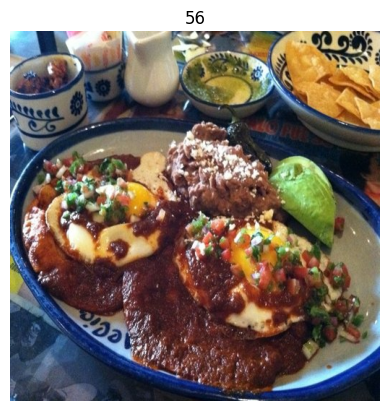

In [34]:
for image,label in train_ds.take(1):
  plt.imshow(image.numpy().astype('uint8'))
  plt.title(str(label.numpy()))
  plt.axis('off')
  plt.show()


In [35]:
print(train_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>


In [36]:
for image,label in train_ds.take(5):
  print(label.numpy())

56
76
21
64
10


In [37]:
print(info.features['image'])
print(info.features['label'])

Image(shape=(None, None, 3), dtype=uint8)
ClassLabel(shape=(), dtype=int64, num_classes=101)


In [38]:
class_names=info.features['label'].names

for image,label in train_ds.take(1):
  index=int(label.numpy())
  print(class_names[index])

huevos_rancheros


In [39]:
print(class_names[:10])

['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


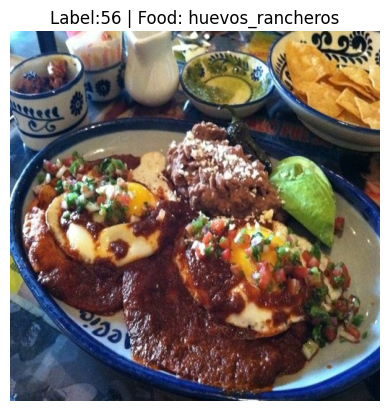

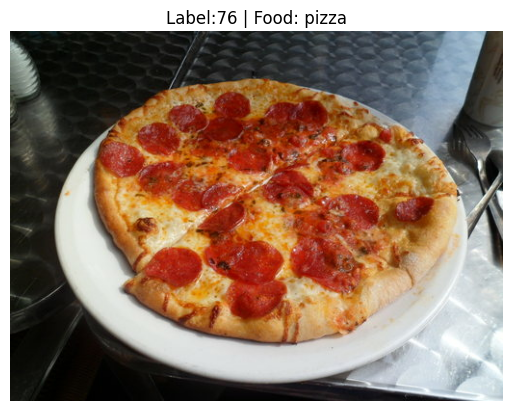

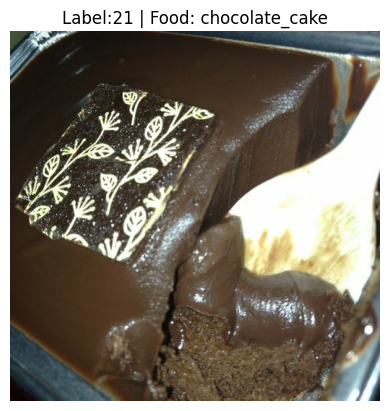

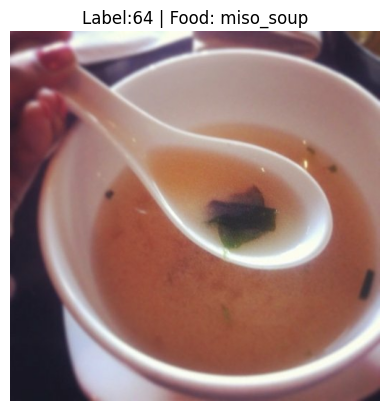

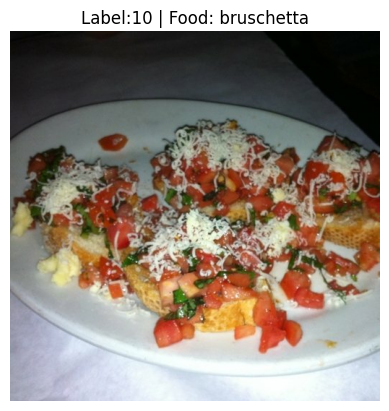

In [40]:
for image,label in train_ds.take(5):
  label_index=int(label.numpy())
  food_name=class_names[label_index]

  plt.imshow(image.numpy())
  plt.title(f"Label:{label_index} | Food: {food_name}")
  plt.axis('off')
  plt.show()

In [41]:
import tensorflow as tf

IMG_SIZE=224
BATCH_SIZE=32

def preprocess(image,label):
  image = tf.cast(image, tf.float32)
  image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

  image = tf.keras.applications.resnet50.preprocess_input(image)

  return image, label

In [42]:
train_ds=train_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds=test_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)
BATCH_SIZE = 32

train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [43]:
# X_train=[]
# X_test=[]
# y_train=[]
# y_test=[]

# for image,label in train_ds:
#   X_train.append(image.numpy())
#   y_train.append(label.numpy())

# X_train=np.array(X_train)
# y_train=np.array(y_train)

# for image,label in test_ds:
#   X_test.append(image.numpy())
#   y_test.append(label.numpy())

# X_test=np.array(X_test)
# y_test=np.array(y_test)





In [48]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Flatten,Dense,BatchNormalization,Dropout,Rescaling,GlobalAveragePooling2D,Input
from keras.applications import ResNet50

In [49]:
base_model=ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable=False

In [50]:
model=Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(base_model)
model.add(GlobalAveragePooling2D())

model.add(Dense(256,activation='relu'))
model.add(BatchNormalization())

model.add(Dense(128,activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(101,activation='softmax'))



In [51]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

history=model.fit(train_ds,validation_data=test_ds,epochs=10)

Epoch 1/10
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 408s 166ms/step - accuracy: 0.4407 - loss: 2.2750 - val_accuracy: 0.5893 - val_loss: 1.5399
Epoch 2/10
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 325s 137ms/step - accuracy: 0.5588 - loss: 1.7114 - val_accuracy: 0.6269 - val_loss: 1.3917
Epoch 3/10
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 324s 137ms/step - accuracy: 0.5969 - loss: 1.5508 - val_accuracy: 0.6336 - val_loss: 1.3573
Epoch 4/10
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 325s 137ms/step - accuracy: 0.6222 - loss: 1.4336 - val_accuracy: 0.6431 - val_loss: 1.3320
Epoch 5/10
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 383s 137ms/step - accuracy: 0.6412 - loss: 1.3494 - val_accuracy: 0.6493 - val_loss: 1.3094
Epoch 6/10
 348/2368 ━━━━━━━━━━━━━━━━━━━━ 3:27 103ms/step - accuracy: 0.6462 - loss: 1.3420